# 02. 사진 넣고 탐지해 보기

**목표**
- 사진 한 장을 넣고 탐지 결과를 받는다
- 결과의 **class / confidence / bbox** 가 무슨 뜻인지 이해한다
- confidence 기준을 바꿔 보며 결과 변화를 본다

In [1]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

## 1. 탐지 실행
예제 사진(버스)으로 시작합니다. 인터넷 주소를 넣으면 사진을 이 폴더에 `bus.jpg` 로 받은 뒤 탐지합니다.

In [2]:
results = model("https://ultralytics.com/images/bus.jpg")
r = results[0]  # 사진 1장 → 결과 1개


image 1/1 c:\LANG_CHAIN_2026\final-project\parkkeeper-jupjup\members\hur-wan\yolo11n-study\bus.jpg: 640x480 4 persons, 1 bus, 6.7ms
Speed: 68.3ms preprocess, 6.7ms inference, 12.9ms postprocess per image at shape (1, 3, 640, 480)


In [8]:
type(results), len(results), type(results[0]), type(results[0].plot()), results[0].plot().shape

(list, 1, ultralytics.engine.results.Results, numpy.ndarray, (1080, 810, 3))

## 2. 결과 그림으로 보기
`r.plot()` 은 박스를 그린 이미지를 돌려줍니다.
OpenCV 형식(BGR)이라서 matplotlib(RGB)로 볼 때는 색 순서를 뒤집습니다 (`[:, :, ::-1]`).

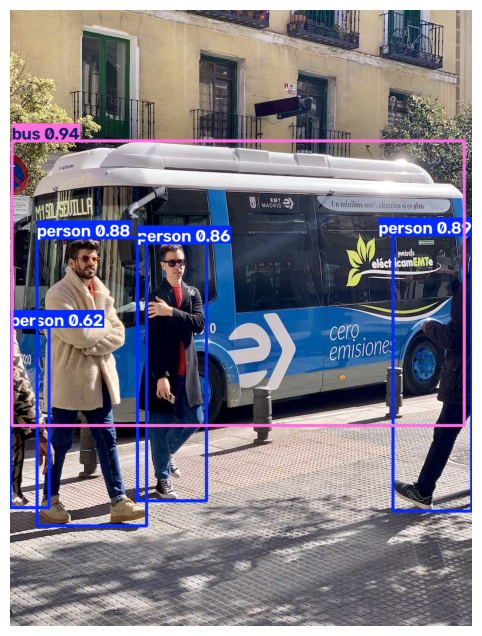

In [ ]:
plt.figure(figsize=(8, 8))
# H, W, RGB
plt.imshow(r.plot()[:, :, ::-1])
plt.axis("off")
plt.show()

## 3. 결과 숫자 읽기
탐지된 물체 하나마다 아래 정보가 있습니다.

| 항목 | 뜻 |
|---|---|
| `cls` | 클래스 번호. `model.names[cls]` 로 이름을 확인 |
| `conf` | confidence. 모델이 얼마나 확신하는지 (0~1) |
| `xyxy` | 박스 좌표 `[왼쪽 x, 위 y, 오른쪽 x, 아래 y]` (픽셀 단위) |

In [10]:
for box in r.boxes:
    cls_id = int(box.cls)
    conf = float(box.conf)
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    print(f"{model.names[cls_id]:10s} conf={conf:.2f}  box=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})")

bus        conf=0.94  box=(4, 229, 796, 728)
person     conf=0.89  box=(671, 395, 810, 879)
person     conf=0.88  box=(47, 400, 239, 904)
person     conf=0.86  box=(223, 409, 344, 860)
person     conf=0.62  box=(0, 556, 69, 872)


In [12]:
r.boxes[0].xyxy

tensor([[  3.8347, 229.3603, 796.1872, 728.4296]], device='cuda:0')

## 4. 속도 보기
`r.speed` 에 단계별 시간(ms)이 들어 있습니다.
첫 실행은 준비 시간 때문에 느리니까, 한 번 더 돌려서 잽니다.

In [13]:
r = model("bus.jpg", verbose=False)[0]
print(r.speed)

total_ms = sum(r.speed.values())
print(f"합계 {total_ms:.1f} ms → 약 {1000 / total_ms:.0f} FPS")

{'preprocess': 3.6371999885886908, 'inference': 11.603199993260205, 'postprocess': 2.0949000027030706}
합계 17.3 ms → 약 58 FPS


## 5. confidence 기준 바꿔 보기
`conf` 보다 확신이 낮은 탐지는 버립니다 (기본값 0.25).

In [14]:
for c in [0.1, 0.25, 0.5, 0.75]:
    r = model("bus.jpg", conf=c, verbose=False)[0]
    names = [model.names[int(k)] for k in r.boxes.cls]
    print(f"conf={c:<5} → {len(names)}개: {names}")

conf=0.1   → 6개: ['bus', 'person', 'person', 'person', 'person', 'skateboard']
conf=0.25  → 5개: ['bus', 'person', 'person', 'person', 'person']
conf=0.5   → 5개: ['bus', 'person', 'person', 'person', 'person']
conf=0.75  → 4개: ['bus', 'person', 'person', 'person']


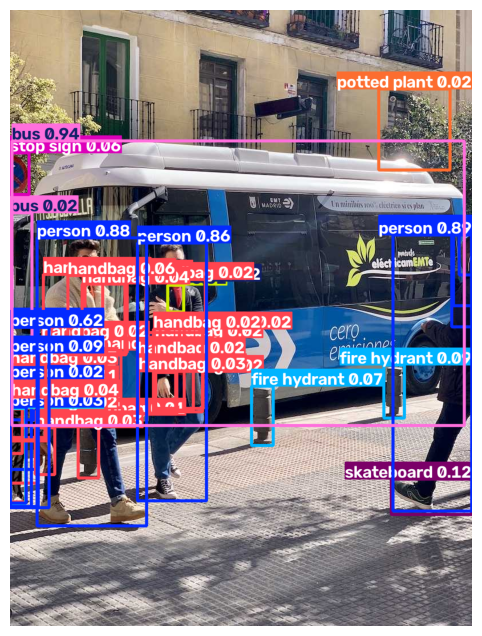

In [19]:
asdfsadf = model("bus.jpg", conf=0.01, verbose=False)[0]
plt.figure(figsize=(8, 8))
plt.imshow(asdfsadf.plot()[:,:,::-1])
plt.axis("off")
plt.show()

## 직접 해보기
1. 페트병, 종이컵, 캔, 비닐 등을 휴대폰으로 찍어서 이 폴더 안 `samples/` 에 넣으세요 (git 에는 안 올라갑니다).
2. 아래 칸에서 파일 이름을 바꿔 가며 탐지해 보고, [evaluation.md](evaluation.md) 의 체크리스트를 채워 보세요.
   - 가까이 / 멀리, 밝은 곳 / 어두운 곳, 바닥 / 잔디 배경


image 1/1 c:\LANG_CHAIN_2026\final-project\parkkeeper-jupjup\members\hur-wan\yolo11n-study\image.png: 480x640 (no detections), 12.4ms
Speed: 2.6ms preprocess, 12.4ms inference, 0.8ms postprocess per image at shape (1, 3, 480, 640)


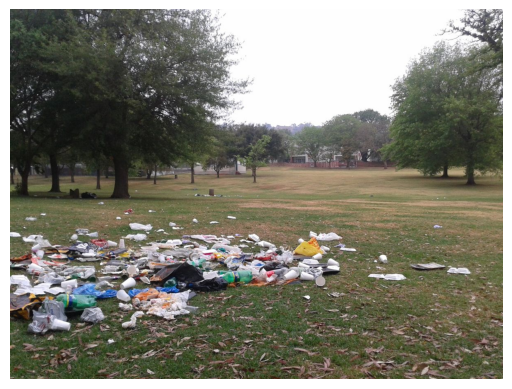

In [28]:
r = model("image.png")[0]
plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off"); plt.show()
for box in r.boxes:
    print("결과 클래스와 확신도")
    print(model.names[int(box.cls)], round(float(box.conf), 2))


image 1/1 c:\LANG_CHAIN_2026\final-project\parkkeeper-jupjup\members\hur-wan\yolo11n-study\image.png: 448x640 1 suitcase, 10.4ms
Speed: 2.3ms preprocess, 10.4ms inference, 2.3ms postprocess per image at shape (1, 3, 448, 640)


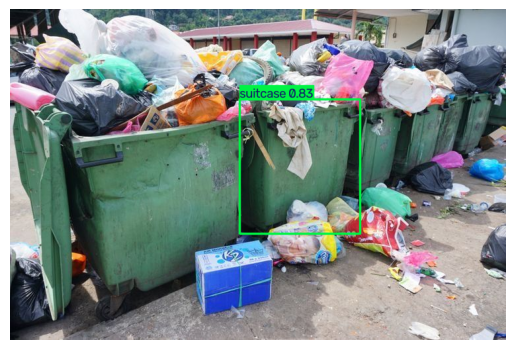

suitcase 0.83


In [31]:
r = model("image.png", conf=0.75)[0]
plt.imshow(r.plot()[:, :, ::-1]); plt.axis("off"); plt.show()
for box in r.boxes:
    print(model.names[int(box.cls)], round(float(box.conf), 2))